# Experiment: regimes invisible to classic detectors (time reversal)

**Design.** Two independent channels each carry a smooth asymmetric wave $s(\phi) = \sin\phi + b\cos 3\phi$ whose phase advances at a fixed frequency plus a small random walk. The regime sets the **direction** in which each channel's phase runs (forward or backward), so the K = 4 regimes are the four direction patterns of the two channels. A random up-projection mixes them into D = 8 channels and white noise (σ = 0.5) is added.

Why classic detectors cannot see the regimes, by construction:
- **Time reversal** of a channel is the same process with its direction flipped. Every statistic that is unchanged by reversing time is therefore identical in all regimes: the marginal law and the autocovariance at every lag, hence the spectrum.
- The channels are independent, so cross-covariances are zero in every regime. The projection and the noise are linear, time-invariant and regime-independent, so all of this survives them.
- Odd harmonics only, $s(\phi + \pi) = -s(\phi)$, make the law symmetric, so **every odd moment vanishes** in expectation: no skewness, coskewness or bispectrum.
- What changes is the waveform's direction in time (its rising and falling edges swap), a **fourth-order** temporal statistic, $E[x_t^3 x_{t+l} - x_t x_{t+l}^3]$, which flips sign with the direction.

Mean, variance, spectral, covariance and Gaussian-likelihood detectors (GMM / HMM / BOCPD / kernel and DMD detectors on raw window statistics) have nothing to work with. A hand-crafted fourth-order asymmetry feature (`raw_asym`) shows that the regimes are nevertheless recoverable from a single window. The question is whether the self-supervised learners discover such structure without being told.

**Protocol** (as in the sines experiment): every available feature learner, including AE / VAE with a linear latent predictor and an untrained `jepa_shared` control, then every registered detector on the test features, scored at sample level. `oracle_clean` here is the asymmetry feature of the noise-free signal: a ceiling.

**Cost.** About 1.5–2 h locally (12 trained networks × 3000 steps on MPS plus the detectors). `CPBENCH_QUICK=1` is a plumbing check whose numbers mean nothing.

In [1]:
import os, json, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from cpbench import Benchmark, make_learner, make_detector, viz
from cpbench.data import Dataset
from cpbench.features import LEARNERS
from cpbench.detectors import DETECTORS
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110, "font.size": 9})
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 80)
warnings.filterwarnings("ignore", message="FastICA did not converge")

QUICK = os.environ.get("CPBENCH_QUICK") == "1"     # ✏️ True: plumbing check only (20 steps, tiny splits)
RUNS = "cpbench_runs_reversal" + ("_quick" if QUICK else "")
OUT = "cpbench_results/reversal_experiment" + ("_quick" if QUICK else "") + ".csv"
print("QUICK" if QUICK else "full run", "->", RUNS)

full run -> cpbench_runs_reversal


## 1. Dataset

`reversal` (cpbench/data/structured.py): `d` channels with frequencies `freq` (cycles per sample), waveform asymmetry `b`, phase diffusion `diff` per sample; with `direction=None` regime k runs channel c backwards when bit c of k is set. With W = 64 a window holds 2–3 periods of each wave. Segments last 640 samples on average, about 10 windows.

In [2]:
# ✏️ the experiment's dataset
DATASET = dict(
    regime=dict(type="markov", K=4, dwell=640),
    sources=[dict(type="reversal", d=2, freq=[0.031, 0.047], b=0.5, diff=0.002)],
    transforms=[dict(type="project", D=8), dict(type="noise", sigma=0.5)],
    seed=0,
    splits=dict(test=[2, 4000], val=[2, 4000]) if QUICK else dict(test=[8, 32000], val=[4, 16000]),
)
W, GAP = 64, 64                         # ✏️ window and context-target gap (samples)
ds = Dataset(DATASET)
data = ds.test_set()
print(ds.info.id)
print(f"K={ds.K}, D={ds.D}, test split {data['obs'].shape}")

markov(dwell=640)|reversal|-|project(D=8)>noise#55ba5463
K=4, D=8, test split (8, 32000, 8)


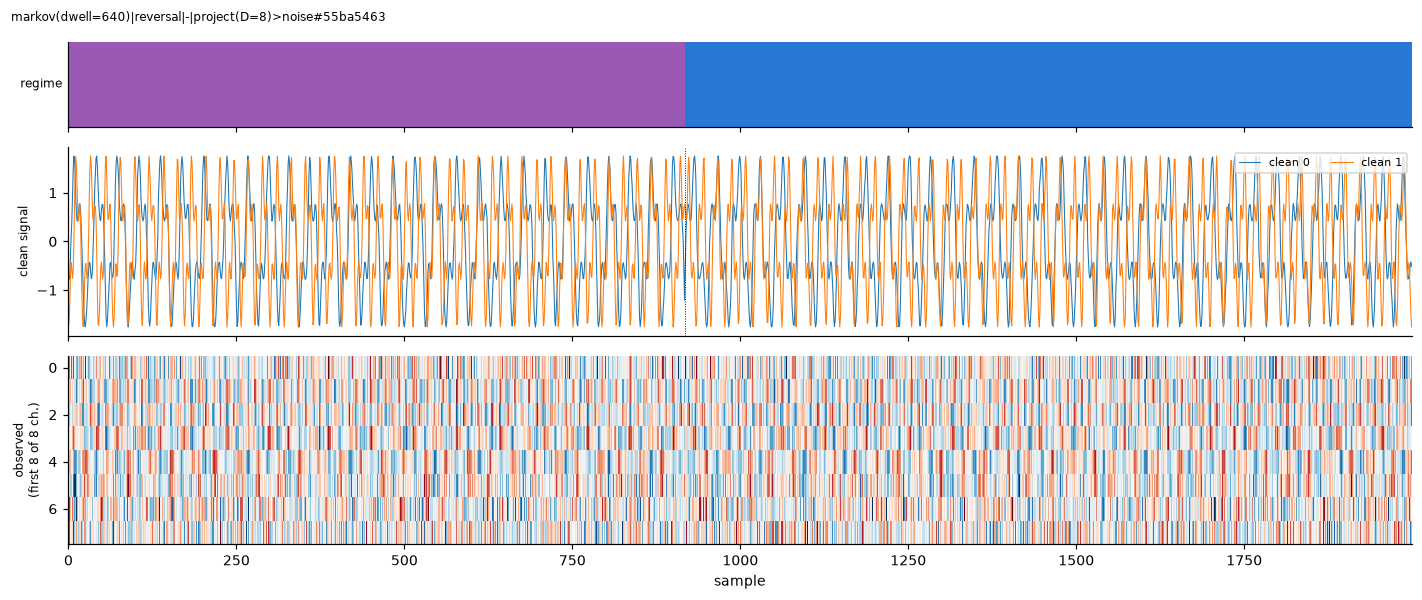

In [3]:
viz.plot_dataset(ds, data, series=0, n=2000)

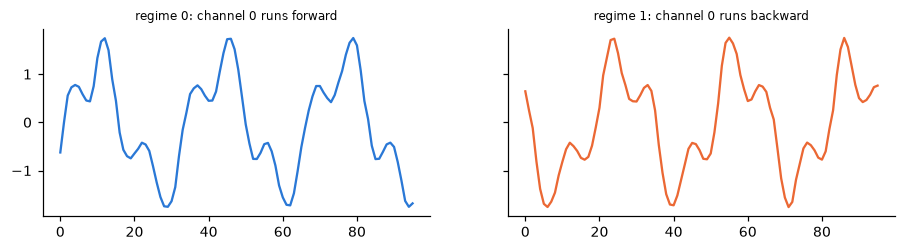

In [4]:
# the waveform of one clean channel in a forward and a backward regime
x, S = data["clean"][..., 0], data["S_s"]
fig, ax = plt.subplots(1, 2, figsize=(10, 2.2), sharey=True)
for a, k in zip(ax, (0, 1)):
    r, t = np.argwhere(S[:, 200:-200] == k)[100]; t += 200
    a.plot(np.arange(96), x[r, t:t + 96], color=viz.COLORS[k]); a.set_title(f"regime {k}: channel 0 runs {'backward' if k & 1 else 'forward'}", fontsize=8)
plt.show()

In [5]:
# check: per-regime statistics of the observations, pooled over 128-sample stretches inside one regime (channel 0 and
# the pair 0-1).  Everything up to third order should agree across regimes; only the fourth-order asymmetry differs.
def regime_stats(x, S, k, L=128):
    segs = np.stack([x[r, t:t + L] for r in range(len(x)) for t in range(0, x.shape[1] - L, L) if (S[r, t:t + L] == k).all()])
    a, b = segs[..., 0], segs[..., 1]
    lag = lambda f, l: float(np.mean(f(a[:, :L - l], a[:, l:])))
    return {"mean": a.mean(), "var": a.var(), "kurtosis": float(((a - a.mean()) ** 4).mean() / a.var() ** 2 - 3),
            **{f"autocov l={l}": lag(lambda u, v: u * v, l) for l in (1, 5, 10)},
            "crosscov 0-1 l=+5": float(np.mean(a[:, :-5] * b[:, 5:])), "crosscov 0-1 l=-5": float(np.mean(a[:, 5:] * b[:, :-5])),
            "skewness": float(((a - a.mean()) ** 3).mean() / a.var() ** 1.5),
            **{f"3rd-order asym l={l}": lag(lambda u, v: u ** 2 * v - u * v ** 2, l) for l in (3, 8)},
            **{f"4th-order asym l={l}": lag(lambda u, v: u ** 3 * v - u * v ** 3, l) for l in (3, 8)}}
x = data["obs"].astype(float)
pd.DataFrame({f"regime {k}": regime_stats(x, data["S_s"], k) for k in range(ds.K)}).round(3)

,regime 0,regime 1,regime 2,regime 3
mean,0.004,0.010,0.012,-0.000
var,1.004,0.997,0.996,0.993
kurtosis,0.004,-0.030,-0.004,0.022
autocov l=1,0.103,0.103,0.088,0.094
autocov l=5,0.003,0.006,0.003,0.001
autocov l=10,-0.082,-0.088,-0.085,-0.087
crosscov 0-1 l=+5,0.007,0.001,0.005,-0.001
crosscov 0-1 l=-5,-0.002,0.003,-0.001,0.004
skewness,-0.020,-0.003,-0.006,-0.004
3rd-order asym l=3,0.009,0.004,0.010,-0.008


## 2. Feature learners and detectors

All registered feature learners are used, except the generic bases (`raw`, `oracle`, `jepa`), which their presets already cover, `oracle_hidden`, which needs a hidden state this dataset does not have.
- Every learner uses the same window W.
- The learners trained on (context, target) pairs also get the gap.
- `oracle_clean` computes the fourth-order asymmetry feature of the noise-free signal: a ceiling, not a competitor. Its default statistic (mean, variance, …), like the spectrum, is identical in every regime here by construction.
- **Control:** `jepa_shared` with `steps=0`, a randomly initialised encoder. A trained learner only counts if it beats this control.

Every registered detector runs with its default parameters, which the ✏️ cell can override. The defaults suit sequences of window features (T = 500 windows per test series here).

The raw baselines × detectors are the classic methods: they should sit at chance (accuracy 0.25), except `raw_asym`, built for this design. `raw_bispec` is zero in expectation, but its single-window estimates fluctuate in a regime-dependent way.

In [6]:
SKIP = {"raw", "oracle", "jepa", "oracle_hidden"}
if ds.D == 1:
    SKIP.add("raw_lagcov")              # lead-lag between channels: undefined on one channel
print("feature learners:", [n for n in LEARNERS.available() if n not in SKIP])
print("detectors:       ", DETECTORS.available())

feature learners: ['ae', 'ae_pred', 'bvae4', 'cpc', 'jepa_mlp_separate', 'jepa_mlp_shared', 'jepa_separate', 'jepa_separate_full', 'jepa_shared', 'oracle_clean', 'raw_asym', 'raw_bispec', 'raw_coskew', 'raw_cov', 'raw_flat', 'raw_lagcov', 'raw_mean', 'raw_spectra', 'raw_stats', 'ts2vec', 'vae', 'vae_pred']
detectors:        ['arhmm', 'bocpd', 'contrast', 'cpdmd', 'dmd_error', 'gmm', 'hmm', 'mmd', 'temporal_excess']


In [7]:
# ✏️ training settings (workers / device / logging do not change the result)
STEPS = 20 if QUICK else 3000
TRAIN = dict(steps=STEPS, batch=128, workers=0 if QUICK else 1, eval_every=max(STEPS // 4, 5), warmup=min(1000, STEPS))

def learner(name, **extra):
    defaults = LEARNERS.defaults(name)
    p = dict(window=W)
    if "gap" in defaults:
        p["gap"] = GAP
    if "steps" in defaults:
        p.update(TRAIN)
    if name == "oracle_clean":
        p["feature"] = "asym"            # the regimes differ only in fourth-order time asymmetry
    return make_learner(name, **{**p, **extra})

FEATURES = [learner(n) for n in LEARNERS.available() if n not in SKIP]
FEATURES.append(learner("jepa_shared", steps=0))   # control: untrained (random) encoder
FIXED = [f for f in FEATURES if not f.trainable]
LEARNT = [f for f in FEATURES if f.trainable]

# ✏️ detectors: every registered one, with optional parameter overrides
OVERRIDES = {}                          # e.g. {"bocpd": dict(hazard=0.1), "cpdmd": dict(w=40, d=10, r=4)}
DETS = [dict(type=n, **OVERRIDES.get(n, {})) for n in DETECTORS.available()]
print(len(FIXED), "fixed and", len(LEARNT), "trained feature learners;", len(DETS), "detectors")

10 fixed and 13 trained feature learners; 9 detectors


## 3. Fit, extract features, detect

The fixed learners run first. Each trained learner is then fitted, or loaded if `RUNS` already holds it, and every detector runs on its features. Results go to `OUT` after each learner, so an interrupted run keeps what it finished.

In [8]:
bench = Benchmark(ds, detectors=DETS, out=RUNS, log=lambda *a: None)
results = []
for f in FIXED + LEARNT:
    results.append(bench.run(f))
    pd.concat(results, ignore_index=True).to_csv(OUT, index=False)
    r = results[-1]; r = r[(r.view == "features") & r.metric.isin(["acc", "cp_ap"])]
    print(f"{f.label():<40}", "  ".join(f"{m} max {r[r.metric == m].value.max():.2f}" for m in ("acc", "cp_ap")))
res = pd.concat(results, ignore_index=True)

oracle_clean(window=64, feature=asym)    acc max 0.95  cp_ap max 0.68
raw_asym(window=64)                      acc max 0.97  cp_ap max 0.81
raw_bispec(window=64)                    acc max 0.70  cp_ap max 0.40
raw_coskew(window=64)                    acc max 0.26  cp_ap max 0.05
raw_cov(window=64)                       acc max 0.27  cp_ap max 0.11
raw_flat(window=64)                      acc max 0.29  cp_ap max 0.35
raw_lagcov(window=64)                    acc max 0.27  cp_ap max 0.06
raw_mean(window=64)                      acc max 0.27  cp_ap max 0.15
raw_spectra(window=64)                   acc max 0.26  cp_ap max 0.20
raw_stats(window=64)                     acc max 0.27  cp_ap max 0.16
ae(window=64, gap=64, steps=3000, batch=128) acc max 0.33  cp_ap max 0.37
ae_pred(window=64, gap=64, steps=3000, batch=128) acc max 0.28  cp_ap max 0.25
bvae4(window=64, gap=64, steps=3000, batch=128) acc max 0.29  cp_ap max 0.39
cpc(window=64, gap=64, steps=3000, batch=128) acc max 0.96  cp_ap max 

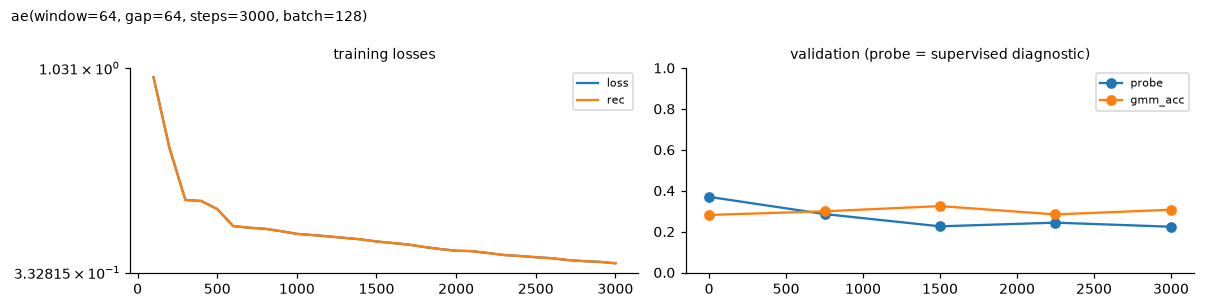

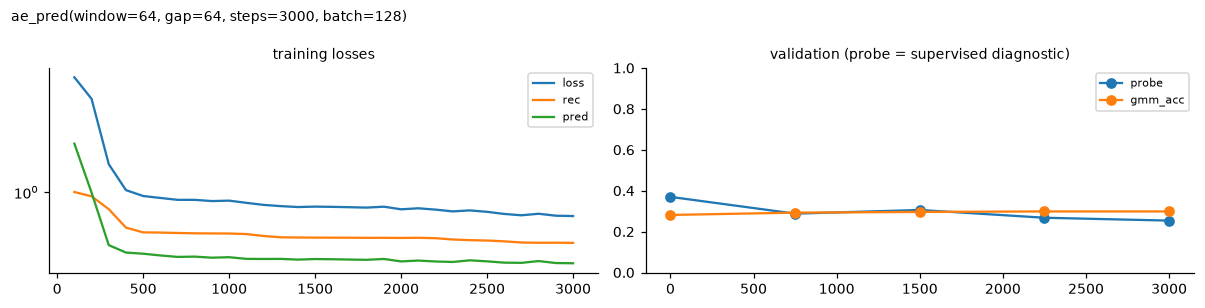

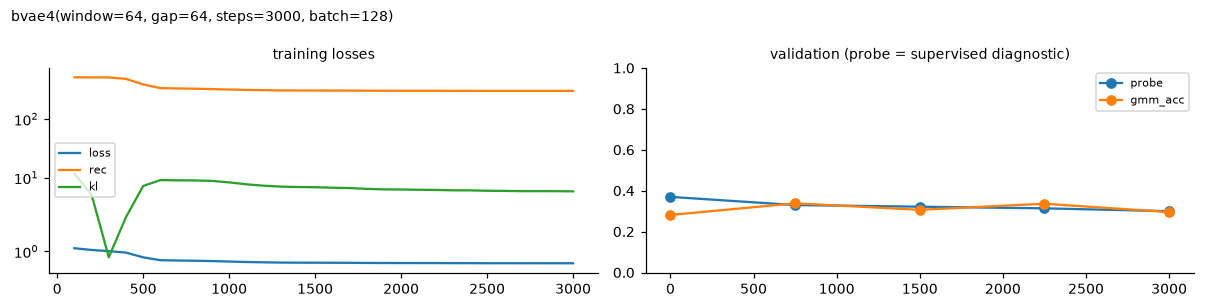

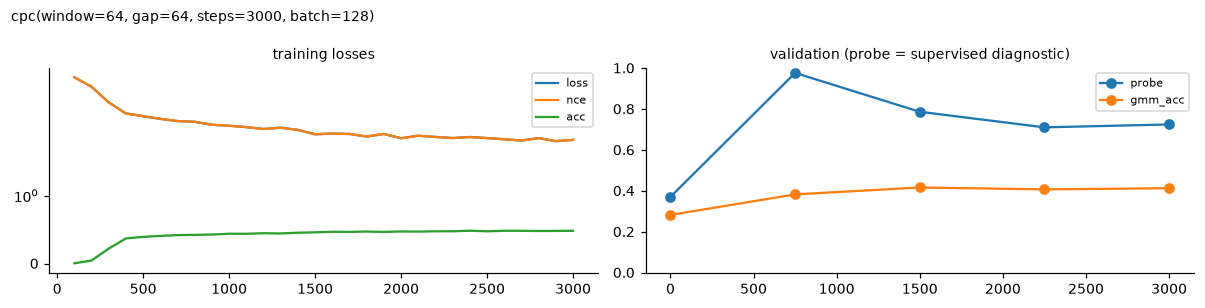

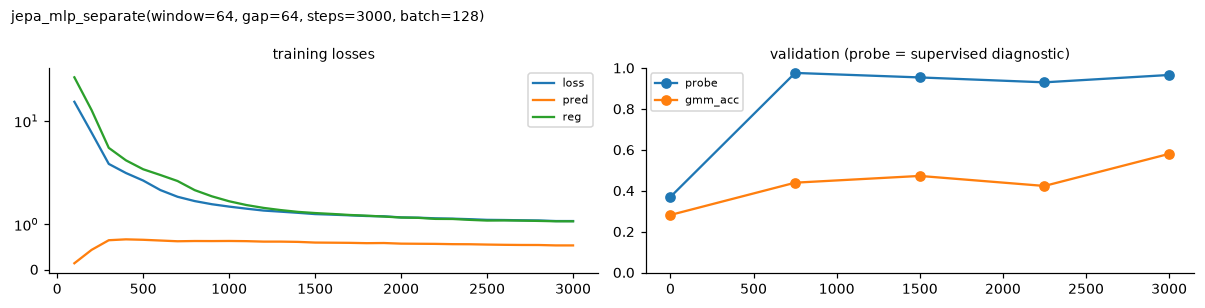

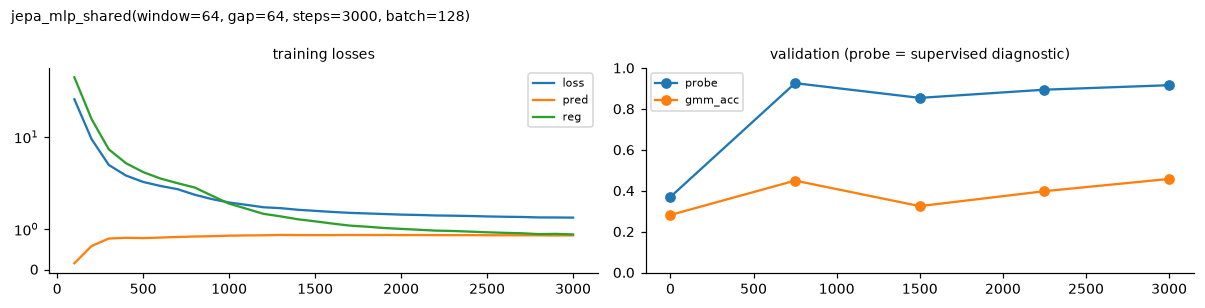

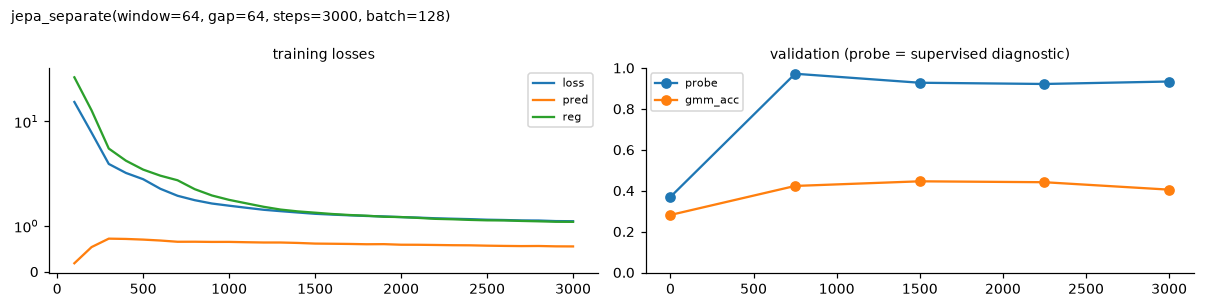

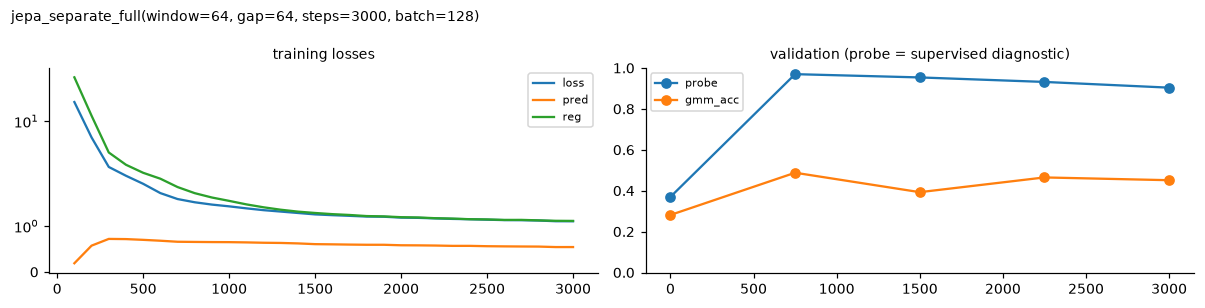

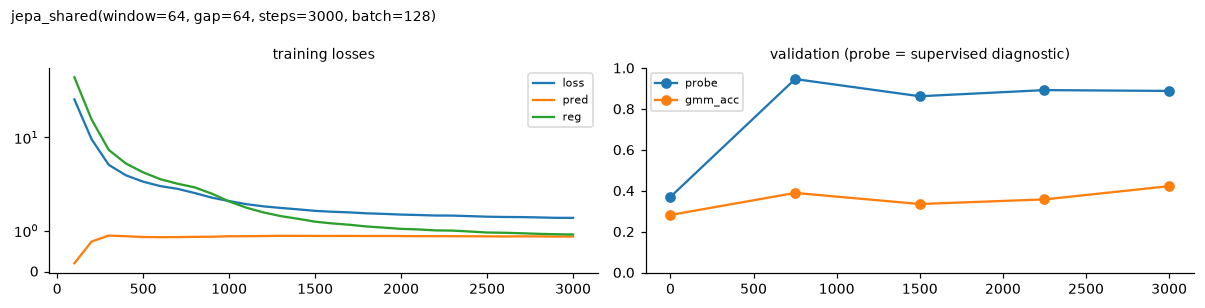

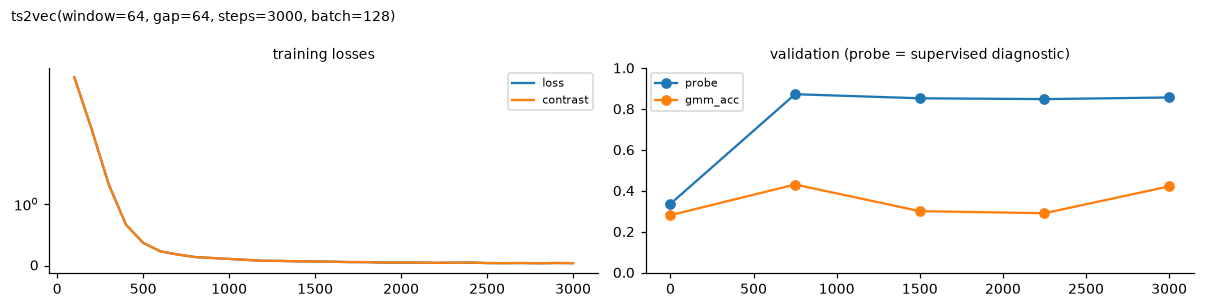

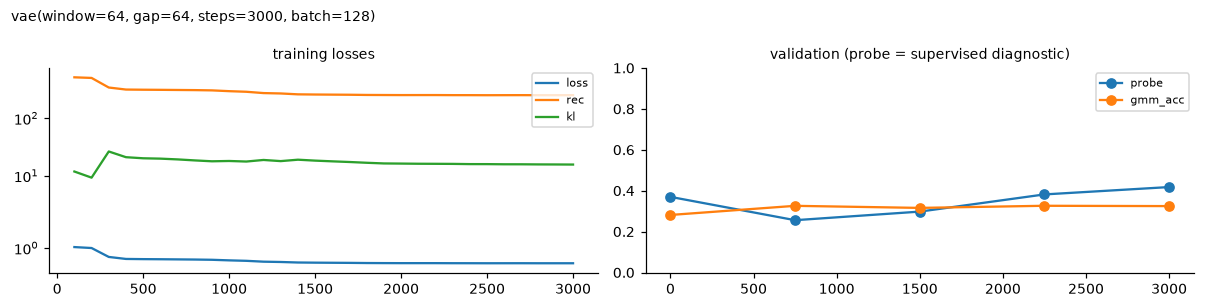

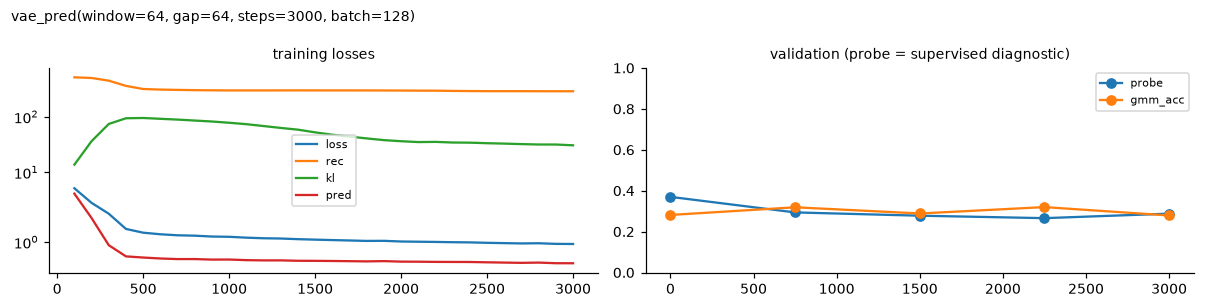

no training log (fixed feature learner?)


In [9]:
# training curves of the trained learners (losses; validation probe and GMM accuracy)
for f in LEARNT:
    viz.plot_training(bench.run_dir(f), title=f.label())

## 4. Results

The heatmaps show every feature learner × detector:
- `acc`: sample-level clustering accuracy after the best label permutation (chance 0.25);
- `cp_ap`: change-point average precision;
- `cp_f1`: F1 at the default threshold, or at the detector's own alarms (CPDMD).

Change-point detectors have no `acc`. Rows are the feature learners and columns the detectors.

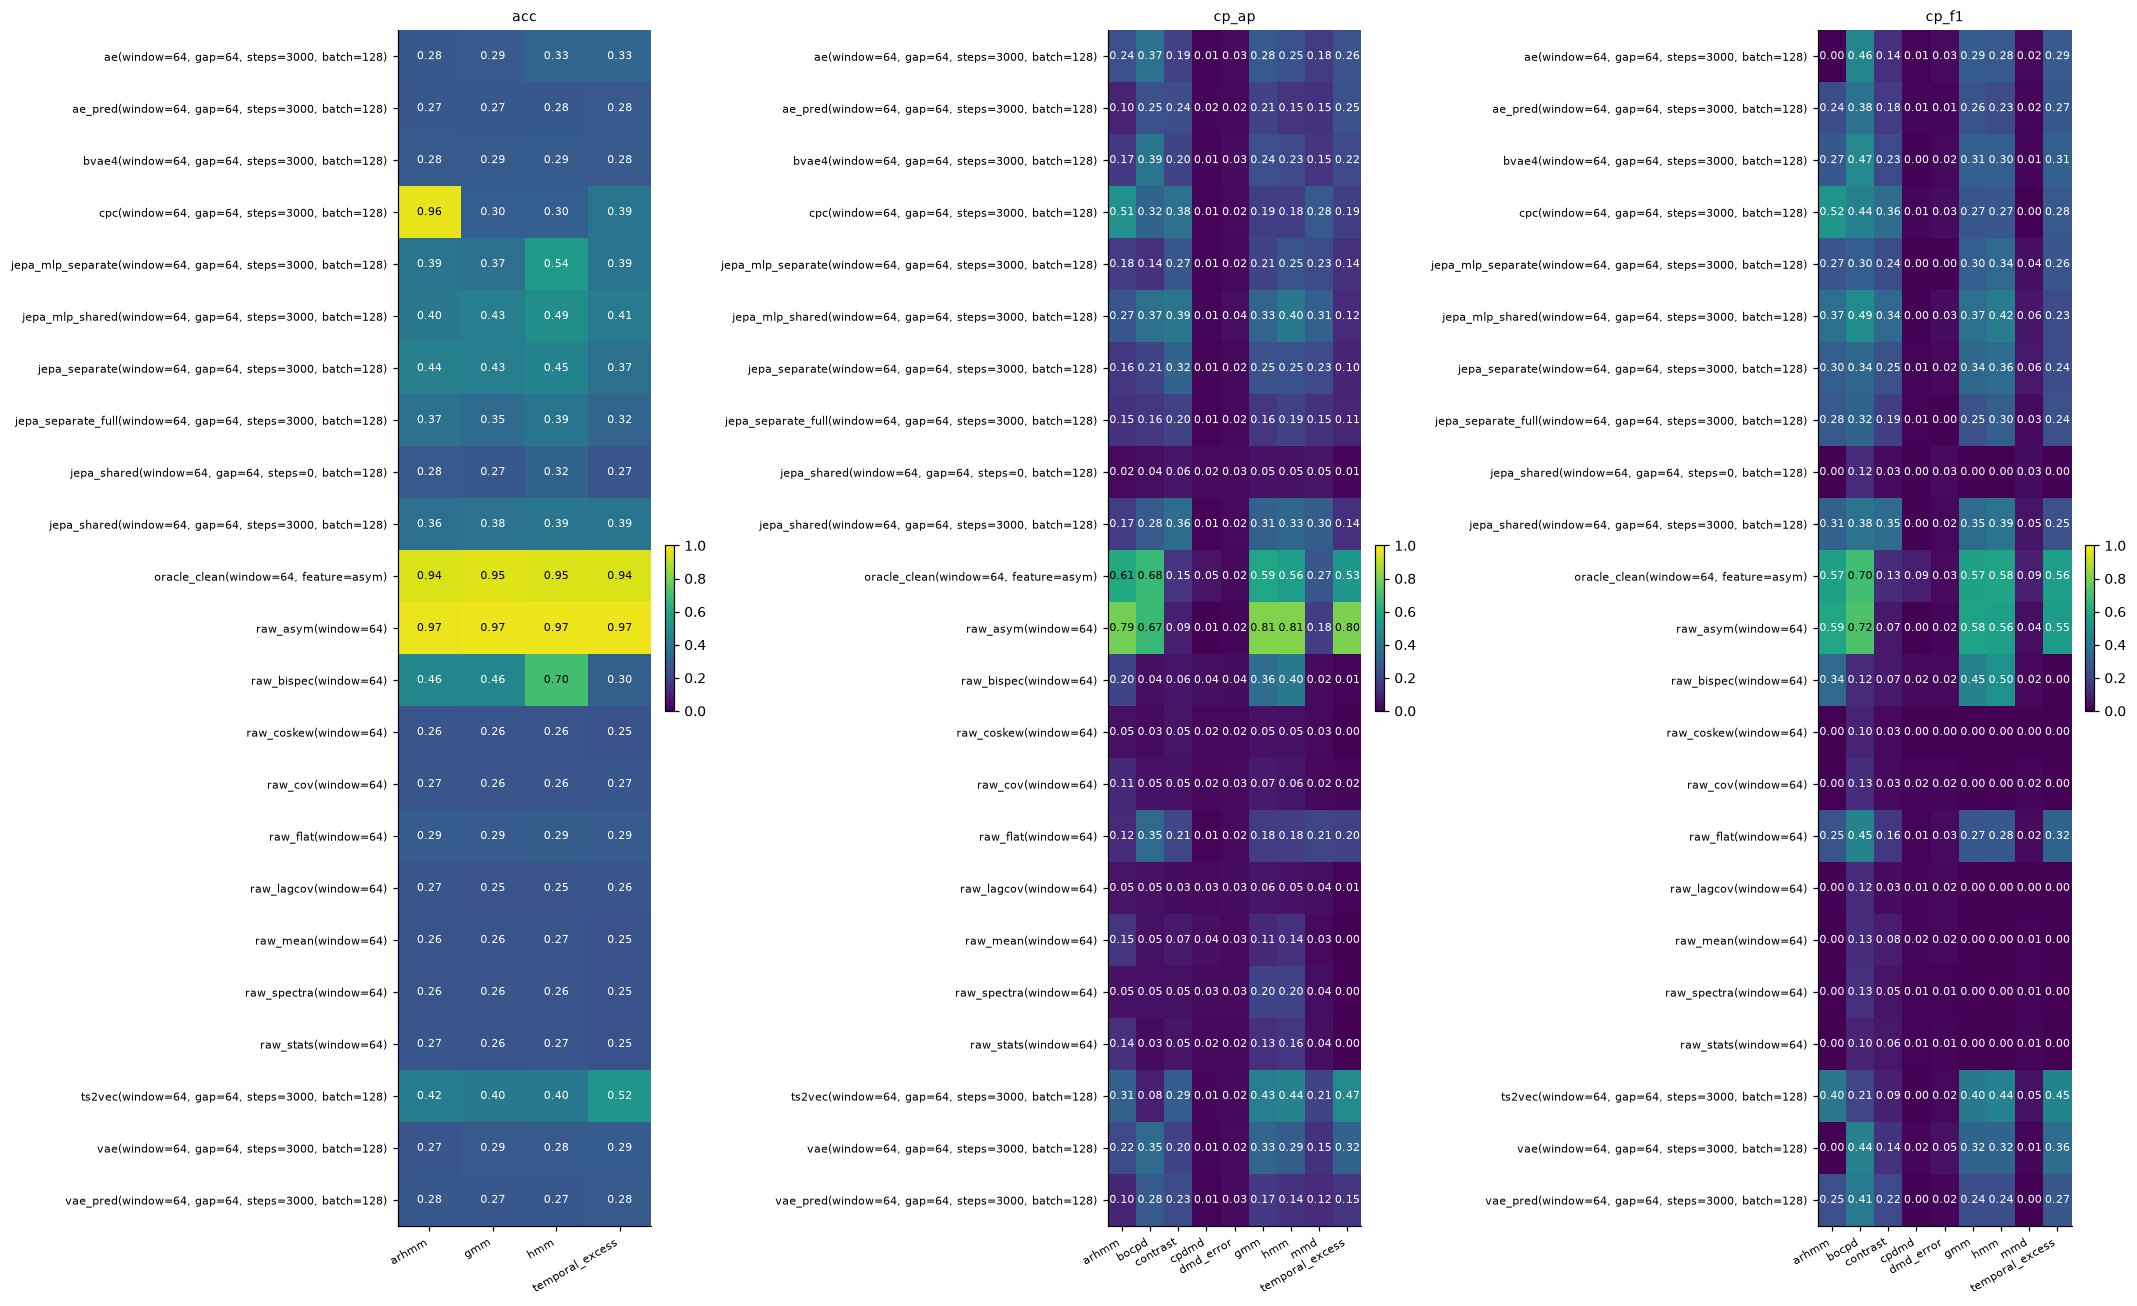

In [10]:
viz.plot_results(res, metrics=("acc", "cp_ap", "cp_f1"))

In [11]:
# best detector per feature learner (clustering accuracy, change-point AP), plus the supervised probe (diagnostic)
f_ = res[res.view == "features"]
best = pd.DataFrame({
    "acc (best clustering detector)": f_[f_.metric == "acc"].groupby("features_label").value.max(),
    "cp_ap (best detector)": f_[f_.metric == "cp_ap"].groupby("features_label").value.max(),
    "linear probe (supervised)": f_[(f_.detector == "probe") & (f_.metric == "probe_linear")].groupby("features_label").value.max(),
})
best.sort_values("acc (best clustering detector)", ascending=False).round(3)

,acc (best clustering detector),cp_ap (best detector),linear probe (supervised)
features_label,,,
raw_asym(window=64),0.974,0.811,0.984
"cpc(window=64, gap=64, steps=3000, batch=128)",0.963,0.507,0.963
"oracle_clean(window=64, feature=asym)",0.952,0.676,0.989
raw_bispec(window=64),0.698,0.400,0.260
"jepa_mlp_separate(window=64, gap=64, steps=3000, batch=128)",0.544,0.270,0.985
"ts2vec(window=64, gap=64, steps=3000, batch=128)",0.520,0.474,0.952
"jepa_mlp_shared(window=64, gap=64, steps=3000, batch=128)",0.494,0.400,0.980
"jepa_separate(window=64, gap=64, steps=3000, batch=128)",0.452,0.318,0.984
"jepa_shared(window=64, gap=64, steps=3000, batch=128)",0.391,0.360,0.978


In [12]:
# full tables
for m in ("acc", "cp_ap", "cp_f1", "cp_covering"):
    t = f_[(f_.metric == m) & (f_.detector != "probe")].pivot_table(index="features_label", columns="detector_label", values="value")
    if len(t):
        print(m); display(t.round(3))

acc


detector_label,arhmm,gmm,hmm,temporal_excess
features_label,,,,
"ae(window=64, gap=64, steps=3000, batch=128)",0.276,0.287,0.329,0.331
"ae_pred(window=64, gap=64, steps=3000, batch=128)",0.271,0.272,0.277,0.277
"bvae4(window=64, gap=64, steps=3000, batch=128)",0.282,0.289,0.290,0.280
"cpc(window=64, gap=64, steps=3000, batch=128)",0.963,0.298,0.297,0.389
"jepa_mlp_separate(window=64, gap=64, steps=3000, batch=128)",0.386,0.369,0.544,0.385
"jepa_mlp_shared(window=64, gap=64, steps=3000, batch=128)",0.400,0.429,0.494,0.409
"jepa_separate(window=64, gap=64, steps=3000, batch=128)",0.435,0.426,0.452,0.370
"jepa_separate_full(window=64, gap=64, steps=3000, batch=128)",0.372,0.349,0.388,0.325
"jepa_shared(window=64, gap=64, steps=0, batch=128)",0.282,0.274,0.319,0.267


cp_ap


detector_label,arhmm,bocpd,contrast,cpdmd,dmd_error,gmm,hmm,mmd,temporal_excess
features_label,,,,,,,,,
"ae(window=64, gap=64, steps=3000, batch=128)",0.245,0.373,0.189,0.011,0.026,0.284,0.250,0.178,0.256
"ae_pred(window=64, gap=64, steps=3000, batch=128)",0.101,0.253,0.238,0.018,0.023,0.206,0.149,0.148,0.247
"bvae4(window=64, gap=64, steps=3000, batch=128)",0.169,0.389,0.204,0.013,0.028,0.242,0.234,0.153,0.222
"cpc(window=64, gap=64, steps=3000, batch=128)",0.507,0.320,0.377,0.009,0.024,0.186,0.183,0.283,0.186
"jepa_mlp_separate(window=64, gap=64, steps=3000, batch=128)",0.177,0.141,0.270,0.008,0.023,0.207,0.255,0.232,0.143
"jepa_mlp_shared(window=64, gap=64, steps=3000, batch=128)",0.267,0.367,0.393,0.014,0.035,0.326,0.400,0.306,0.118
"jepa_separate(window=64, gap=64, steps=3000, batch=128)",0.159,0.207,0.318,0.009,0.023,0.248,0.254,0.228,0.105
"jepa_separate_full(window=64, gap=64, steps=3000, batch=128)",0.148,0.159,0.199,0.009,0.022,0.160,0.194,0.145,0.109
"jepa_shared(window=64, gap=64, steps=0, batch=128)",0.025,0.036,0.060,0.025,0.027,0.049,0.047,0.053,0.012


cp_f1


detector_label,arhmm,bocpd,contrast,cpdmd,dmd_error,gmm,hmm,mmd,temporal_excess
features_label,,,,,,,,,
"ae(window=64, gap=64, steps=3000, batch=128)",0.000,0.456,0.137,0.009,0.031,0.292,0.280,0.023,0.288
"ae_pred(window=64, gap=64, steps=3000, batch=128)",0.237,0.376,0.176,0.014,0.013,0.258,0.229,0.019,0.274
"bvae4(window=64, gap=64, steps=3000, batch=128)",0.273,0.473,0.226,0.004,0.021,0.305,0.304,0.014,0.310
"cpc(window=64, gap=64, steps=3000, batch=128)",0.519,0.440,0.357,0.014,0.033,0.266,0.273,0.005,0.279
"jepa_mlp_separate(window=64, gap=64, steps=3000, batch=128)",0.267,0.300,0.236,0.000,0.004,0.298,0.340,0.042,0.264
"jepa_mlp_shared(window=64, gap=64, steps=3000, batch=128)",0.365,0.485,0.343,0.005,0.034,0.365,0.418,0.060,0.233
"jepa_separate(window=64, gap=64, steps=3000, batch=128)",0.299,0.336,0.248,0.009,0.020,0.339,0.360,0.064,0.237
"jepa_separate_full(window=64, gap=64, steps=3000, batch=128)",0.279,0.321,0.187,0.009,0.004,0.248,0.304,0.028,0.243
"jepa_shared(window=64, gap=64, steps=0, batch=128)",0.000,0.122,0.031,0.005,0.026,0.000,0.005,0.031,0.000


cp_covering


detector_label,arhmm,bocpd,contrast,cpdmd,dmd_error,gmm,hmm,mmd,temporal_excess
features_label,,,,,,,,,
"ae(window=64, gap=64, steps=3000, batch=128)",0.036,0.609,0.236,0.128,0.270,0.497,0.518,0.072,0.527
"ae_pred(window=64, gap=64, steps=3000, batch=128)",0.515,0.582,0.267,0.114,0.188,0.477,0.496,0.073,0.491
"bvae4(window=64, gap=64, steps=3000, batch=128)",0.480,0.613,0.387,0.148,0.231,0.493,0.513,0.089,0.541
"cpc(window=64, gap=64, steps=3000, batch=128)",0.751,0.657,0.446,0.134,0.369,0.504,0.507,0.038,0.559
"jepa_mlp_separate(window=64, gap=64, steps=3000, batch=128)",0.574,0.566,0.351,0.108,0.212,0.506,0.574,0.088,0.528
"jepa_mlp_shared(window=64, gap=64, steps=3000, batch=128)",0.598,0.664,0.452,0.135,0.203,0.535,0.589,0.082,0.551
"jepa_separate(window=64, gap=64, steps=3000, batch=128)",0.588,0.598,0.316,0.105,0.234,0.560,0.587,0.105,0.528
"jepa_separate_full(window=64, gap=64, steps=3000, batch=128)",0.553,0.607,0.332,0.099,0.185,0.522,0.551,0.098,0.538
"jepa_shared(window=64, gap=64, steps=0, batch=128)",0.036,0.467,0.140,0.076,0.183,0.036,0.046,0.136,0.036


## 5. Inspecting decisions

Below, every detector's decisions on the trained learner with the best clustering accuracy, against the truth, then the 2-D PCA of a few feature spaces coloured by the true regime.

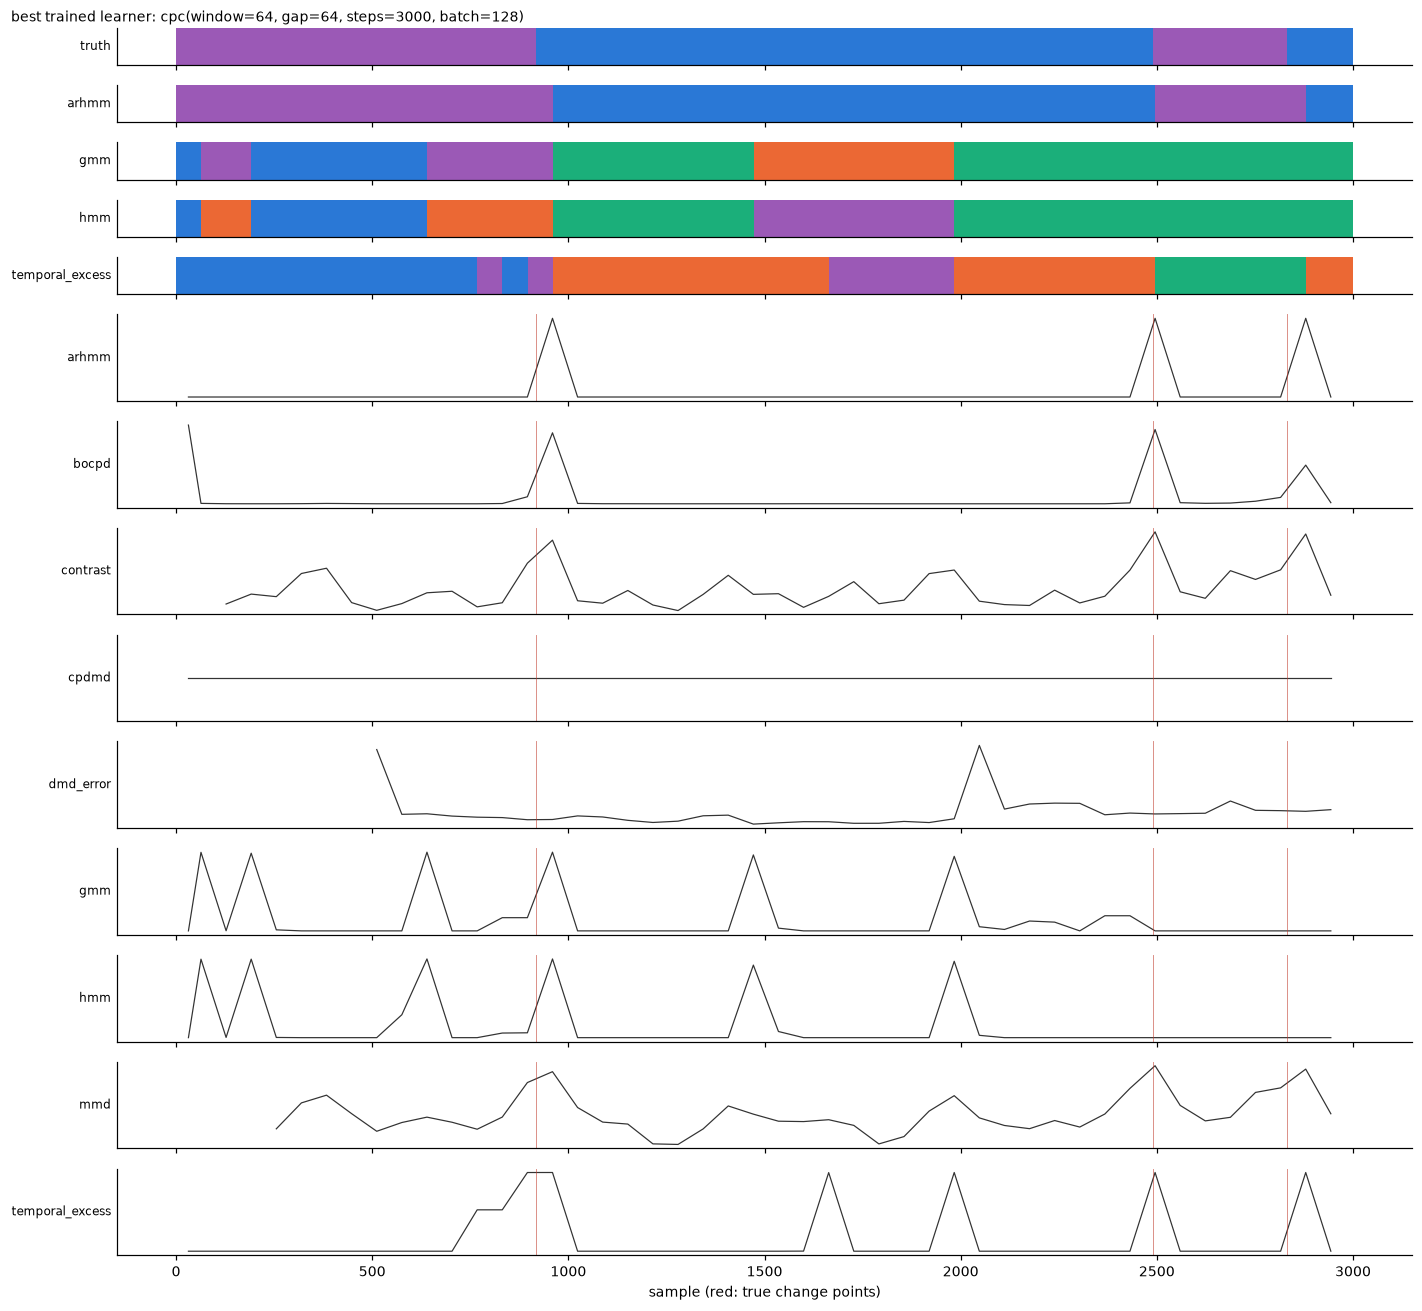

In [13]:
acc = f_[(f_.metric == "acc") & f_.features.isin([f.name for f in LEARNT])].groupby("features_label").value.max()
top = next(f for f in LEARNT if f.label() == acc.idxmax()) if len(acc) else LEARNT[0]
dec, starts = bench.decisions(top)
viz.plot_decisions(data, dec, starts, top.window, ds.K, title=f"best trained learner: {top.label()}", n=3000)

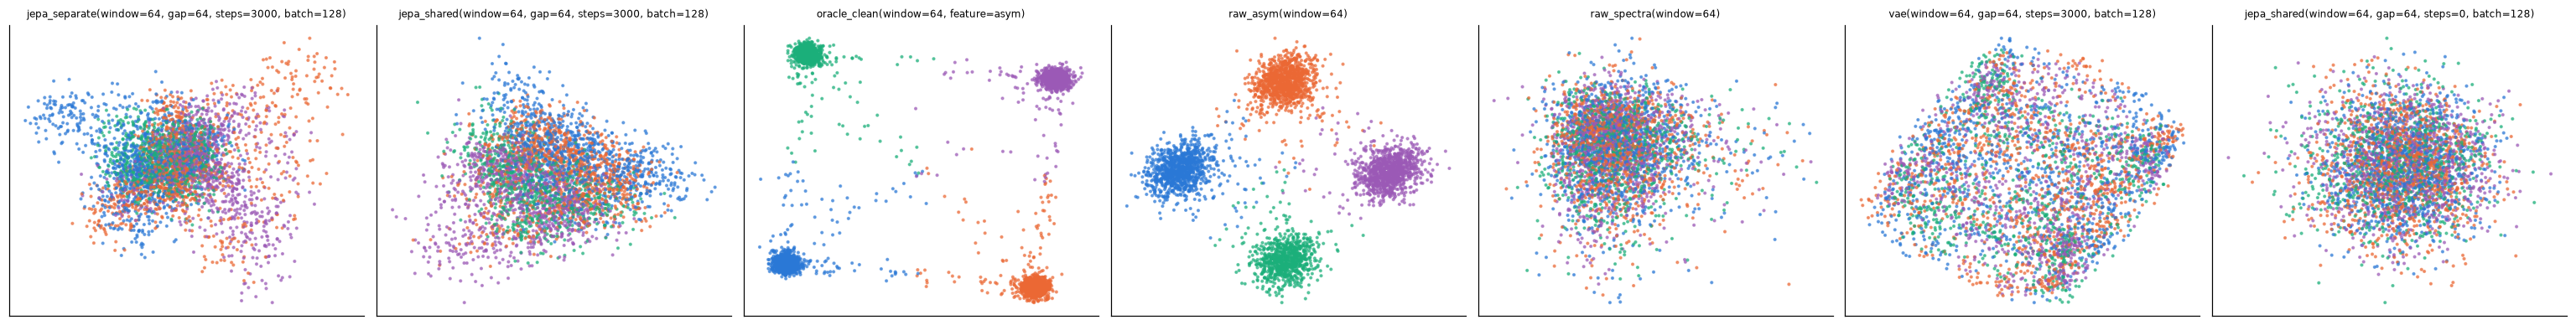

In [14]:
show = [f for f in FEATURES if f.name in ("raw_spectra", "raw_asym", "oracle_clean", "jepa_shared", "jepa_separate", "vae")]
views = {f.label(): bench.features(f)[0]["features"] for f in show}
viz.plot_features(views, data, bench.features(show[0])[1], W, ds.K)

In [15]:
# separate-design JEPAs also expose their target encoder's features: the same detectors on that view
t = res[(res.view == "target") & res.metric.isin(["acc", "cp_ap"])]
if len(t):
    display(t.pivot_table(index="features_label", columns=["metric", "detector_label"], values="value").round(3))

metric                                                          acc                                cp_ap                                                                      
detector_label                                                arhmm    gmm    hmm temporal_excess  arhmm  bocpd contrast  cpdmd dmd_error    gmm    hmm    mmd temporal_excess
features_label                                                                                                                                                                
jepa_mlp_separate(window=64, gap=64, steps=3000, batch=128)   0.793  0.687  0.687           0.527  0.567  0.297    0.583  0.012     0.032  0.577  0.573  0.484           0.398
jepa_separate(window=64, gap=64, steps=3000, batch=128)       0.630  0.522  0.516           0.520  0.390  0.323    0.594  0.012     0.016  0.555  0.548  0.468           0.426
jepa_separate_full(window=64, gap=64, steps=3000, batch=128)  0.459  0.508  0.508           0.465  0.364  0.253    0.436  0.014     0.023  0.452  0.453  0.342           0.369